In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

In [61]:
stock_list =["^DJI", "^GSPC","^IXIC",]
datos_historicos = yf.download(stock_list, end='2000-12-8', start='2000-1-8')
datos_historicos.to_csv('C:\\Users\\super\\OneDrive\\Escritorio\\base_acciones.csv')
datos_historicos = pd.read_csv('C:\\Users\\super\\OneDrive\\Escritorio\\base_acciones.csv',header=[0,1] ,index_col=0, parse_dates=True)
datos_historicos = datos_historicos.select_dtypes(include=[np.number])

c:\Users\super\AppData\Local\Programs\Python\Python314\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\super\AppData\Local\Programs\Python\Python314\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
c:\Users\super\AppData\Local\Programs\Python\Python314\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename

In [62]:
def get_data(datos_historicos):
    if 'Adj Close' in datos_historicos.columns:
        precios = datos_historicos['Adj Close']
    else:
        precios = datos_historicos
    
    returns = precios.pct_change().dropna()
    mean_returns = returns.mean()
    covmatrix = returns.cov()
    return mean_returns, covmatrix

In [63]:
mean_returns, covmatrix = get_data(datos_historicos)
print(mean_returns)

Price   Ticker
Close   ^DJI     -0.000290
        ^GSPC    -0.000259
        ^IXIC    -0.001225
High    ^DJI     -0.000317
        ^GSPC    -0.000286
        ^IXIC    -0.001343
Low     ^DJI     -0.000294
        ^GSPC    -0.000223
        ^IXIC    -0.001103
Open    ^DJI     -0.000264
        ^GSPC    -0.000185
        ^IXIC    -0.001110
Volume  ^DJI      0.028387
        ^GSPC     0.021684
        ^IXIC     0.016470
dtype: float64


In [64]:
weights = np.random.random(len(mean_returns))
weights /= np.sum(weights)
print(weights)


[0.01178018 0.11552426 0.06761156 0.13728669 0.00675308 0.03794838
 0.03308061 0.0178785  0.00248675 0.00246948 0.04132832 0.16412751
 0.19385194 0.04266207 0.12521068]


In [65]:
initial_investment = 10000

In [66]:
#monte carlo simulation
mc_simulations = 100
time_horizon = 60
meanM =meanM = np.full(shape=(time_horizon, len(weights)), fill_value=mean_returns).transpose()

portafolio_sims = np.full(shape=(time_horizon, mc_simulations), fill_value=0.0)

for m in range (0, mc_simulations):
    Z = np.random.normal(size=(time_horizon, len(weights)))
    L = np.linalg.cholesky(covmatrix)
    daily_returns = meanM + np.inner(L, Z)
    portafolio_sims[:, m] = np.cumprod(np.inner(weights, daily_returns.T) + 1)



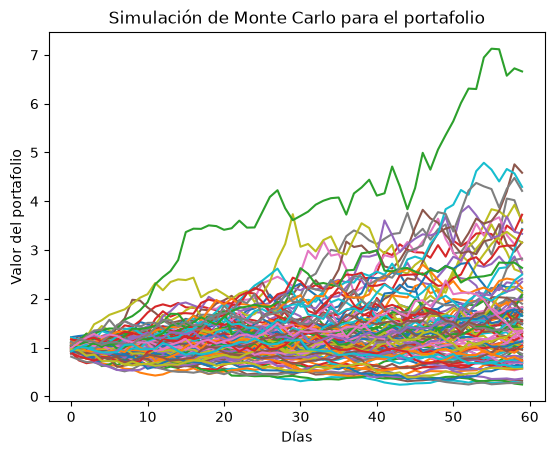

In [67]:
plt.plot(portafolio_sims)
plt.title('Simulación de Monte Carlo para el portafolio')
plt.xlabel('Días')
plt.ylabel('Valor del portafolio')
plt.show()

In [68]:
russell = yf.download('^RUT', end='2000-12-8', start='2000-1-8')
russell.to_csv('C:\\Users\\super\\OneDrive\\Escritorio\\base_russell.csv')
russell = pd.read_csv('C:\\Users\\super\\OneDrive\\Escritorio\\base_russell.csv',header=[0,1],index_col=0, parse_dates=True)
russell = russell.select_dtypes(include=[np.number])
russell = russell.drop(russell.index[1:3])
#importamos los datos

c:\Users\super\AppData\Local\Programs\Python\Python314\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\super\AppData\Local\Programs\Python\Python314\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
c:\Users\super\AppData\Local\Programs\Python\Python314\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename


c:\Users\super\AppData\Local\Programs\Python\Python314\Lib\site-packages\yfinance\multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
c:\Users\super\AppData\Local\Programs\Python\Python314\Lib\site-packages\yfinance\multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.sort_index(level=0, axis=1, inplace=True)


In [69]:
#calculamos la funcion de german-klass para medir la volatilidad del portafolio
def german_klass(russell ,dias = 21):
    termino_1 = 0.5*np.log(russell['High'] / russell['Low'])**2
    termino_2 = (2*np.log(2) - 1)*(np.log(russell['Close'] / russell['Open']))**2
    terminos = termino_1 - termino_2
    volatilidad = np.sqrt(terminos.rolling(window=dias).mean()) 
    return volatilidad
#creamos nuestra funcion de german klass para medir la volatildad ,es mejor que la varianza porque esta toma precios de apertura y cierra ,la varianza solo de cierre ,si habre 30 y cierra en 50 ,pero el dia anterior estaba en 50 segun la varianza no habria volatilidad con este metodo podemos ser mas precisos tambien es mas preciso porque tenemos el max y el minimo podemos ver que tan pesada fue la batalla entre compradores y vendedores.
    

In [70]:
russell_volatility = german_klass(russell, dias=60)

Text(44.207222222222214, 0.5, 'Volatilidad')

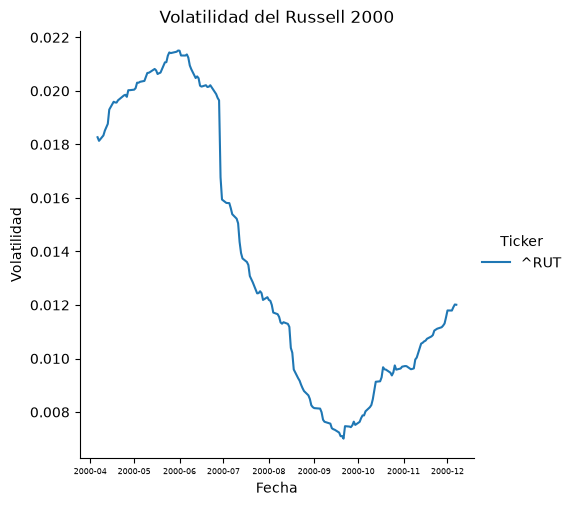

In [71]:
import seaborn as sns
g=sns.relplot(data=russell_volatility, kind="line")
g.tick_params(axis='x', labelsize=6)
plt.title('Volatilidad del Russell 2000')
plt.xlabel('Fecha')
plt.ylabel('Volatilidad')
 #podemos apreciar que la volatilidad al principio del periodo cuando estallo la crisis(dot com) una volatilidad de hasta el 22% algo que se refleja en montecarlo ,para el mes 10 bajo rapidamente ,para luego quedar en el 12% .


            

In [72]:
nasdaq = yf.download("^IXIC",end='2000-12-8',start='2000-1-8')
nasdaq.to_csv('C:\\Users\\super\\OneDrive\\Escritorio\\nasdaq.csv')
nasdaq = pd.read_csv('C:\\Users\\super\\OneDrive\\Escritorio\\nasdaq.csv', header=[0,1], index_col=0, parse_dates=True)
nasdaq = nasdaq.select_dtypes(include=[np.number])
nasdaq = nasdaq.drop(nasdaq.index[1:3])

c:\Users\super\AppData\Local\Programs\Python\Python314\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\super\AppData\Local\Programs\Python\Python314\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
c:\Users\super\AppData\Local\Programs\Python\Python314\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename

In [73]:
def german_klass(nasdaq ,dias = 21):
    termino_1 = 0.5*np.log(nasdaq['High'] / nasdaq['Low'])**2
    termino_2 = (2*np.log(2) - 1)*(np.log(nasdaq['Close'] / nasdaq['Open']))**2
    terminos = termino_1 - termino_2
    volatilidad = np.sqrt(terminos.rolling(window=dias).mean()) 
    return volatilidad

Text(44.03888888888888, 0.5, 'Volatilidad')

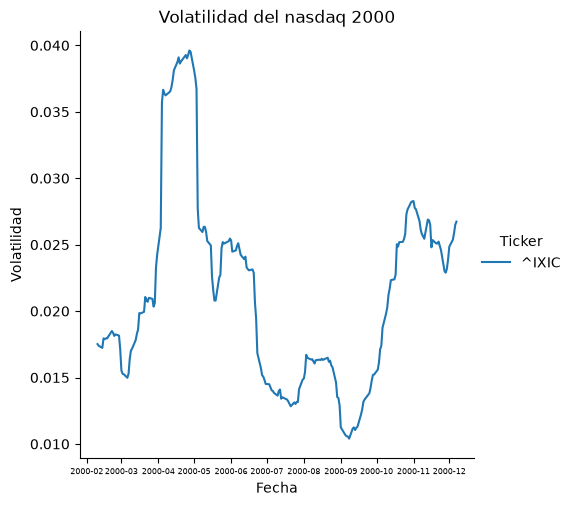

In [74]:
nasdaq_volatility =german_klass(nasdaq ,dias = 21)

g=sns.relplot(data=nasdaq_volatility, kind="line")
g.tick_params(axis='x', labelsize=6)
plt.title('Volatilidad del nasdaq 2000')
plt.xlabel('Fecha')
plt.ylabel('Volatilidad')